In [31]:
import numpy as np
import pandas as pd

In [32]:
np.random.seed(42)

df = pd.DataFrame({
    'Customer_ID': range(1001, 1201),
    'Monthly_Spending': np.random.exponential(
        scale=3000,
        size=200
    ).round(2)
})

df.head()

,Customer_ID,Monthly_Spending
0,1001,1407.80
1,1002,9030.36
2,1003,3950.24
3,1004,2738.83
4,1005,508.87


<Axes: >

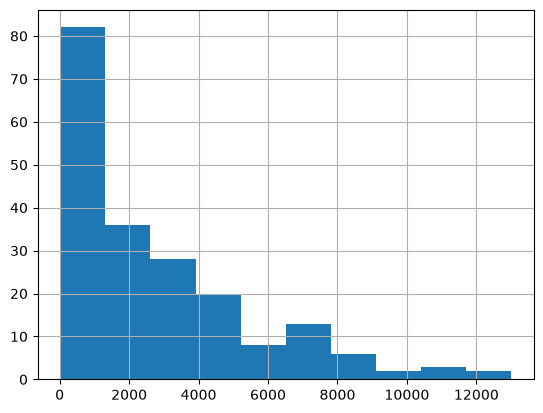

In [33]:
df['Monthly_Spending'].hist()

In [34]:
df['Monthly_Spending'].skew()

np.float64(1.3766763183119268)

In [35]:
from sklearn.preprocessing import FunctionTransformer

In [36]:
log_transformer = FunctionTransformer(
    func=np.log1p,
    inverse_func=np.expm1
)

In [37]:
Log_Spending = log_transformer.fit_transform(df[['Monthly_Spending']])

In [38]:
df['Monthly_Spending'].skew()

np.float64(1.3766763183119268)

In [39]:
Log_Spending.skew()

Monthly_Spending   -0.827919
dtype: float64

array([[<Axes: title={'center': 'Monthly_Spending'}>]], dtype=object)

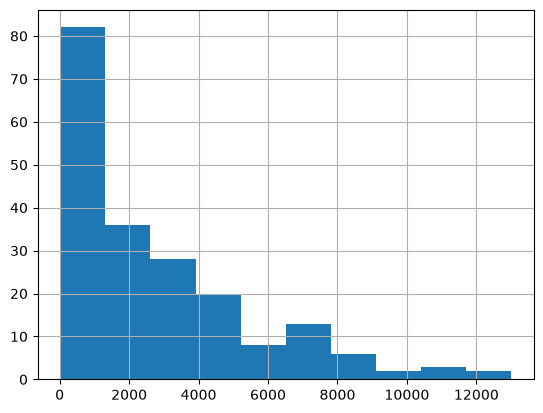

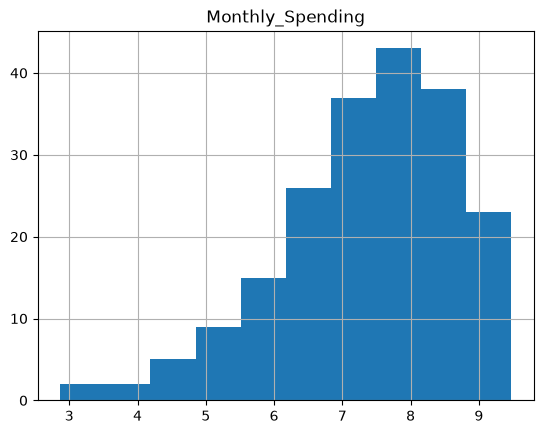

In [40]:
df['Monthly_Spending'].hist()
Log_Spending.hist()

In [41]:
original_values = log_transformer.inverse_transform(Log_Spending)

print(original_values.shape)

(200, 1)


In [44]:
comparison = pd.DataFrame({
    'Original': df['Monthly_Spending'],
    'Log_Transformed': Log_Spending.to_numpy().ravel(),
    'Recovered': original_values.to_numpy().ravel()
})

comparison.head()

,Original,Log_Transformed,Recovered
0,1407.80,7.250494,1407.80
1,9030.36,9.108458,9030.36
2,3950.24,8.281785,3950.24
3,2738.83,7.915651,2738.83
4,508.87,6.234156,508.87


In [47]:
np.random.seed(42)

n = 300

df_ml = pd.DataFrame({
    'Age': np.random.randint(18, 61, n),
    'Monthly_Spending': np.random.exponential(
        scale=3000, size=n
    ).round(2),
    'Website_Visits': np.random.randint(1, 21, n)
})

probability = (
    0.10
    + (df_ml['Website_Visits'] * 0.02)
    + (df_ml['Monthly_Spending'] > 3000) * 0.15
)

probability = np.clip(probability, 0, 0.95)

df_ml['Purchased'] = np.random.binomial(1, probability)

df_ml.head()

,Age,Monthly_Spending,Website_Visits,Purchased
0,56,3107.79,5,0
1,46,3316.22,6,1
2,32,5989.00,3,1
3,60,784.82,5,0
4,25,2074.61,5,1


In [48]:
from sklearn.model_selection import train_test_split

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    df_ml.drop(columns='Purchased'), df_ml['Purchased'], 
    test_size = 0.2, random_state = 42, stratify = df_ml[['Purchased']]
)

In [57]:
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.compose import ColumnTransformer

In [60]:
CT = ColumnTransformer(
    transformers=[
        ('std_scaler', StandardScaler(),
        ['Age','Website_Visits']),
        ('ft', FunctionTransformer(
            func=np.log1p,
            inverse_func=np.expm1),
         ['Monthly_Spending'])],
    remainder='passthrough'
)

In [62]:
X_train_transformed = CT.fit_transform(X_train)
X_test_transformed = CT.transform(X_test)

In [63]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [75]:
pipe = Pipeline([
    ('preprocessing', CT),
    ('model', LogisticRegression(max_iter=1000))
])

In [76]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Age','Monthly_Spending','Website_Visits']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('std_scaler', ...), ('ft', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatw

In [77]:
y_pred = pipe.predict(X_test)

In [78]:
from sklearn.metrics import accuracy_score

In [79]:
accuracy_score(y_test, y_pred)

0.65

In [80]:
from sklearn.metrics import confusion_matrix

In [81]:
confusion_matrix(y_test, y_pred)

array([[39,  0],
       [21,  0]])

In [82]:
from sklearn.metrics import precision_score

In [83]:
precision_score(y_test, y_pred)

C:\Users\chauh\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


0.0

In [84]:
from sklearn.metrics import recall_score

In [87]:
recall_score(y_test, y_pred)

0.0

In [88]:
from sklearn.metrics import classification_report

In [89]:
classification_report(y_test, y_pred)

C:\Users\chauh\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\chauh\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\chauh\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

'              precision    recall  f1-score   support\n\n           0       0.65      1.00      0.79        39\n           1       0.00      0.00      0.00        21\n\n    accuracy                           0.65        60\n   macro avg       0.33      0.50      0.39        60\nweighted avg       0.42      0.65      0.51        60\n'